# Context Engineering From Scratch: Clear What the Agent Already Used

**An expense-audit agent checks 30 reports, one per step. By the last step it is re-reading every report it already finished. This notebook measures what that costs, clears it with about ten lines of plain Python, and reports what changed and what did not.**

## The one idea

The model sees only what is in the context window at this step, and the loop decides what goes in. A bare agent loop only ever adds: every tool result and every document stays in the message list and is sent again on every later step. **Context engineering** is deciding, for every step, what goes into the window and what stays out ([Anthropic, 2025](https://www.anthropic.com/engineering/effective-context-engineering-for-ai-agents)). The cheapest move is also the first one to try: once the agent has acted on a result, replace the full text with a one-line note of what it found. That is a deletion, not a model call.

## Overview

1. Build 30 synthetic expense reports with 11 planted violations, so the score is exact
2. Run the audit the default way, keeping every report in the history, and log the tokens per layer
3. Clear each report once it has been answered, and run again
4. Clear in batches instead, to protect the prompt cache, and run a third time
5. Compare tokens, dollars, the size of the last call, and the audit score
6. An aside the data forced on us: the false alarms, and why they are not a context problem

**Requirements:** `pip install openai tiktoken matplotlib` and an `OPENAI_API_KEY`. The three runs make 90 calls to `gpt-5.4-mini` and cost about $0.20 together at the list prices of 2026-10-30. Outputs saved in this notebook come from a real run. Yours will differ a little, because the model is not deterministic.

In [1]:
# !pip install openai tiktoken matplotlib
import os, json, random, time
import openai, tiktoken
import matplotlib.pyplot as plt

MODEL = "gpt-5.4-mini"
# USD per 1M tokens, from https://developers.openai.com/api/docs/pricing on 2026-10-30. Check yours.
PRICE = {"input": 0.75, "cached_input": 0.075, "output": 4.50}
client = openai.OpenAI()          # reads OPENAI_API_KEY from the environment
enc = tiktoken.get_encoding("o200k_base")   # only used to split a call into layers; totals come from the API

## 1. A job with a known answer

The agent audits travel expense reports against a short policy. Each report has the receipts that matter, plus the noise real reports carry: a card statement, an approval chain, notes. Each one is about 1,200 tokens.

The generator plants 11 violations and records them as ground truth, so every run can be scored exactly. It also plants a near miss in every report: the employee's home office is always a city with a *higher* hotel cap than the city the hotel is in. Checking a hotel night against the wrong city's cap is the classic way an auditor, human or model, waves a violation through.

In [2]:
CAPS = {"New York": 320, "San Francisco": 300, "Boston": 260, "Seattle": 250, "Chicago": 240, "Austin": 210, "Denver": 200}
MEAL_CAP = 75
POLICY = "TRAVEL AND EXPENSE POLICY (FY2026)\n\n" \
    "Rule H - Hotel nightly cap. A hotel night may not exceed the cap for the city THE HOTEL IS IN:\n" + \
    "\n".join(f"  {c}: ${v}/night" for c, v in CAPS.items()) + f"""
Rule M - Meals. Meals may not exceed ${MEAL_CAP} per day, per traveler.
Rule D - Receipts. Every receipt must show a date. A receipt with no date is a violation.
Caps apply to the nightly room rate as shown on the receipt.
Card statement lines, approval chains and notes are context only; they are not receipts."""

HOTELS = {"New York": "The Lexington", "San Francisco": "Hotel Zephyr", "Boston": "The Verb Hotel", "Seattle": "Hotel Theodore",
          "Chicago": "The Robey", "Austin": "The Driskill", "Denver": "The Crawford Hotel"}
NAMES = ["Dana Levi", "Omar Haddad", "Mia Chen", "Lucas Brandt", "Priya Nair", "Tom Okafor", "Sara Weiss", "Noa Peretz",
         "Ivan Petrov", "Emma Rossi", "Yuki Sato", "Ben Carter", "Lea Martin", "Ravi Shah", "Ana Costa"]
NOISE = ["Airport parking T2", "In-flight wifi", "Office Depot", "Hertz fuel top-up", "Amtrak seat upgrade",
         "Conference badge reprint", "Laundry service", "Phone charger, Best Buy", "FedEx Office printing",
         "Checked bag fee", "Toll road E-ZPass", "Zoom Pro renewal", "Luggage storage", "SIM card, T-Mobile"]

def make_reports(n=30, seed=7):
    rng, cities = random.Random(seed), list(CAPS)
    kinds = {}                                   # report index -> planted violation
    for i in rng.sample(range(n // 2), 2): kinds[i] = "H"
    for i in rng.sample([x for x in range(n // 2, n) if x not in kinds], 5): kinds[i] = "H"   # most hotel violations come late
    for i in rng.sample([x for x in range(n) if x not in kinds], 2): kinds[i] = "M"
    for i in rng.sample([x for x in range(n) if x not in kinds], 2): kinds[i] = "D"
    reports, truth, city_of = [], set(), {}
    for i in range(n):
        rid, city = f"R-{i+1:02d}", cities[(i * 3) % len(cities)]
        home = rng.choice([c for c in cities if CAPS[c] > CAPS[city]] or cities)   # the near miss
        rate = CAPS[city] - rng.choice([5, 10, 15, 20, 30])
        if kinds.get(i) == "H":
            rate = CAPS[city] + rng.choice([10, 15, 25]); truth.add((rid, "H"))     # over this city's cap, under the home office's
        nights, day0 = rng.choice([2, 3, 4]), rng.randint(1, 20)
        lines = [f"EXPENSE REPORT {rid}", f"Employee: {NAMES[i % len(NAMES)]}   Home office: {home}   Cost center: CC-{4100 + i}",
                 f"Trip: client workshop in {city}, {nights} nights, September 2026", "", "RECEIPTS"]
        lines += [f"- 2026-09-{day0 + d:02d}  Hotel: {HOTELS[city]}, {city} - 1 night - ${rate}.00" for d in range(nights)]
        for d in range(nights):
            meal = rng.choice([38, 44, 52, 57, 61, 66, 70])
            if kinds.get(i) == "M" and d == nights - 1:
                meal = MEAL_CAP + rng.choice([12, 19, 27]); truth.add((rid, "M"))
            lines.append(f"- 2026-09-{day0 + d:02d}  Meals, {city} - ${meal}.00")
        if kinds.get(i) == "D": truth.add((rid, "D"))
        lines.append(f"- {'(no date)' if kinds.get(i) == 'D' else f'2026-09-{day0:02d}'}  Taxi from airport, {city} - ${rng.randint(35, 80)}.00")
        lines += ["", "CORPORATE CARD STATEMENT (context only)"]
        lines += [f"  2026-09-{rng.randint(1, 28):02d}  POS {rng.randint(100000, 999999)}  {rng.choice(NOISE):<36} ${rng.randint(3, 60)}.{rng.randint(0, 99):02d}  auth {rng.randint(1000, 9999)}"
                  for _ in range(rng.randint(26, 32))]
        lines.append(f"  2026-09-{day0:02d}  POS {rng.randint(100000, 999999)}  {HOTELS[city]} folio, {nights} nights       ${rate * nights}.00")
        lines += ["", "APPROVAL CHAIN (context only)"]
        lines += [f"  {k + 1}. {who} on 2026-10-{rng.randint(1, 9):02d}, ticket FIN-{rng.randint(10000, 99999)}, comment: \"{rng.choice(['ok', 'see attached', 'client billable', 'per diem per policy', 'n/a'])}\""
                  for k, who in enumerate(["Submitted by employee", "Reviewed by team lead", "Pending finance review"])]
        lines += ["", "NOTES", f"  Workshop agenda attached separately. Client PO {rng.randint(400000, 499999)}. Home office {home} travel desk booked the flights."]
        reports.append("\n".join(lines)); city_of[rid] = city
    return reports, truth, city_of

REPORTS, TRUTH, CITY_OF = make_reports()
print(f"{len(REPORTS)} reports, about {sum(len(enc.encode(r)) for r in REPORTS) // len(REPORTS):,} tokens each")
print("planted violations:", sorted(TRUTH))
print("\n" + REPORTS[2][:900] + "\n...")

30 reports, about 1,177 tokens each
planted violations: [('R-02', 'D'), ('R-03', 'H'), ('R-05', 'M'), ('R-06', 'H'), ('R-14', 'M'), ('R-16', 'H'), ('R-17', 'H'), ('R-22', 'H'), ('R-24', 'H'), ('R-26', 'H'), ('R-28', 'D')]

EXPENSE REPORT R-03
Employee: Mia Chen   Home office: Chicago   Cost center: CC-4102
Trip: client workshop in Denver, 2 nights, September 2026

RECEIPTS
- 2026-09-20  Hotel: The Crawford Hotel, Denver - 1 night - $215.00
- 2026-09-21  Hotel: The Crawford Hotel, Denver - 1 night - $215.00
- 2026-09-20  Meals, Denver - $38.00
- 2026-09-21  Meals, Denver - $70.00
- 2026-09-20  Taxi from airport, Denver - $44.00

CORPORATE CARD STATEMENT (context only)
  2026-09-05  POS 596493  Checked bag fee                      $49.15  auth 2011
  2026-09-11  POS 815476  FedEx Office printing                $36.71  auth 8905
  2026-09-26  POS 914208  In-flight wifi                       $59.71  auth 1930
  2026-09-08  POS 300599  Amtrak seat upgrade                  $5.98  auth 2601
 

## 2. The audit loop, the default way

One report per step, and the model answers with a structured list of violations. The loop keeps everything, which is what every loop does unless you tell it otherwise: the policy at the top, then every report and every answer, in order. The step that checks report 30 sends reports 1 to 29 again, although the agent finished with them long ago.

The answers stay in the history in every mode. They are short, and they are the agent's record of what it found.

One parameter, `clear_every`, controls the only thing that differs between the three runs in this notebook:

- `0` keeps every report (the default loop)
- `1` replaces each report with a one-line note once the model has answered it
- `5` does the same in batches of five, for reasons section 4 explains

In [3]:
SYSTEM = POLICY + '''

You are an expense auditor. Each message gives you one expense report.
Answer with the report id and the list of receipts that break a rule (empty if none).
For each, give the rule, the receipt line, the amount, and the limit you checked it against (0 for rule D).'''

ANSWER = {"type": "json_schema", "json_schema": {"name": "audit", "strict": True, "schema": {
    "type": "object", "additionalProperties": False, "required": ["report_id", "violations"],
    "properties": {"report_id": {"type": "string"}, "violations": {"type": "array", "items": {
        "type": "object", "additionalProperties": False, "required": ["rule", "receipt", "amount", "limit"],
        "properties": {"rule": {"type": "string", "enum": ["H", "M", "D"]}, "receipt": {"type": "string"},
                       "amount": {"type": "number"}, "limit": {"type": "number"}}}}}}}}

def call_model(messages):
    for attempt in range(5):
        try:
            return client.chat.completions.create(model=MODEL, messages=messages, response_format=ANSWER)
        except (openai.RateLimitError, openai.APIConnectionError, openai.InternalServerError):
            if attempt == 4: raise
            time.sleep(5 * (attempt + 1))

def layers(messages):
    # Estimated tokens per layer of one call: instructions, history, current request
    n = lambda m: len(enc.encode(m["content"]))
    return {"instructions": n(messages[0]), "history": sum(n(m) for m in messages[1:-1]), "current": n(messages[-1])}

def run_audit(clear_every=0):
    messages = [{"role": "system", "content": SYSTEM}]
    answers, log, uncleared = {}, [], []
    for step, report in enumerate(REPORTS, 1):
        rid = f"R-{step:02d}"
        # --- the whole technique: once a report has been answered, keep the finding and drop the text ---
        if clear_every and uncleared and (step - 1) % clear_every == 0:
            for i, old in uncleared:
                found = "; ".join(f"{v['rule']} {v['amount']:g} vs {v['limit']:g}" for v in answers[old]) or "none"
                messages[i]["content"] = f"{old}: checked, full text cleared. Found: {found}"
            uncleared = []
        uncleared.append((len(messages), rid))
        messages.append({"role": "user", "content": report})
        est = layers(messages)
        reply = call_model(messages)
        u = reply.usage
        cached = (u.prompt_tokens_details.cached_tokens or 0) if u.prompt_tokens_details else 0
        text = reply.choices[0].message.content
        messages.append({"role": "assistant", "content": text})
        answers[rid] = json.loads(text)["violations"]
        log.append({"step": step, "input": u.prompt_tokens, "cached": cached, "output": u.completion_tokens, **est})
    return answers, log

def score(answers):
    got = {(rid, v["rule"]) for rid, vs in answers.items() for v in vs}
    wrong_cap = sorted({rid for rid, vs in answers.items() for v in vs if v["rule"] == "H" and v["limit"] != CAPS[CITY_OF[rid]]})
    return {"caught": len(got & TRUTH), "missed": sorted(TRUTH - got), "false_alarms": sorted(got - TRUTH), "wrong_cap": wrong_cap}

def cost(log):
    i, c, o = (sum(r[k] for r in log) for k in ("input", "cached", "output"))
    return ((i - c) * PRICE["input"] + c * PRICE["cached_input"] + o * PRICE["output"]) / 1e6

def summary(name, answers, log):
    s = score(answers)
    print(f"{name}: {sum(r['input'] for r in log):,} input tokens sent ({sum(r['cached'] for r in log) / sum(r['input'] for r in log):.0%} cached), "
          f"last call {log[-1]['input']:,} tokens, ${cost(log):.3f}")
    print(f"  caught {s['caught']}/{len(TRUTH)} planted violations, missed {s['missed'] or 'none'}, "
          f"wrong city cap used on {s['wrong_cap'] or 'no report'}, {len(s['false_alarms'])} false alarms")

## 3. Run it, and log every layer

Before changing anything, measure: log the tokens in each layer at every step. Here there are three layers: the instructions (the policy, re-sent on every call), the history (every earlier report and answer), and the current request (this step's report).

In [4]:
keep_answers, keep_log = run_audit(clear_every=0)
for r in keep_log:
    if r["step"] in (1, 2, 10, 20, 30):
        print(f"step {r['step']:2d}: instructions {r['instructions']:>4} | history {r['history']:>6,} | current {r['current']:>5,}"
              f"   -> API counted {r['input']:>6,} input tokens, {r['cached']:>6,} of them cached")
summary("Keep everything", keep_answers, keep_log)

step  1: instructions  214 | history      0 | current 1,088   -> API counted  1,389 input tokens,  1,280 of them cached
step  2: instructions  214 | history  1,100 | current 1,160   -> API counted  2,574 input tokens,  2,432 of them cached
step 10: instructions  214 | history 10,895 | current 1,210   -> API counted 12,523 input tokens, 11,136 of them cached
step 20: instructions  214 | history 23,619 | current 1,238   -> API counted 25,405 input tokens, 23,936 of them cached
step 30: instructions  214 | history 36,244 | current 1,205   -> API counted 38,127 input tokens, 36,608 of them cached
Keep everything: 587,070 input tokens sent (94% cached), last call 38,127 tokens, $0.080
  caught 9/11 planted violations, missed [('R-03', 'H'), ('R-24', 'H')], wrong city cap used on no report, 10 false alarms


By the last step, almost the entire call is history: reports the agent already finished, sent again. The current report, the only thing this step needs to read, is a small slice at the bottom.

Note the `cached` column. OpenAI caches the start of a prompt when it repeats the previous request exactly ([prompt caching docs](https://platform.openai.com/docs/guides/prompt-caching)), and an append-only history repeats exactly. So most of those re-sent tokens are billed at a tenth of the price. Keep that in mind for section 4.

## 4. Clear what the agent already used

Same loop, `clear_every=1`. Before each call, the previous report's full text is replaced with one line, and the agent's answer stays in the history:

```text
R-03: checked, full text cleared. Found: H 215 vs 200
```

Nothing is lost that the run still needs: the finding is kept, and the original report is still in `REPORTS` if a later step had to look it up again. A real agent would get a `read_report` tool for that.

In [5]:
clear_answers, clear_log = run_audit(clear_every=1)
summary("Clear each report once answered", clear_answers, clear_log)

Clear each report once answered: 108,086 input tokens sent (31% cached), last call 5,927 tokens, $0.074
  caught 11/11 planted violations, missed none, wrong city cap used on no report, 20 false alarms


### Clearing has a price: the cache

Editing a message in the middle of the history changes the prompt from that point on, and the cache discount stops at the first changed token. The usual advice is to let used results pile up for a few steps and clear them in one batch, so most calls still repeat the previous prefix exactly. Here is the batch version, `clear_every=5`:

In [6]:
batch_answers, batch_log = run_audit(clear_every=5)
summary("Clear in batches of 5", batch_answers, batch_log)

Clear in batches of 5: 158,012 input tokens sent (71% cached), last call 9,673 tokens, $0.055
  caught 10/11 planted violations, missed [('R-03', 'H')], wrong city cap used on no report, 12 false alarms


## 5. Side by side

                                    input sent  cached  last call    cost  caught wrong cap
Keep everything                        587,070     94%     38,127  $0.080    9/11         0
Clear each report once answered        108,086     31%      5,927  $0.074   11/11         0
Clear in batches of 5                  158,012     71%      9,673  $0.055   10/11         0


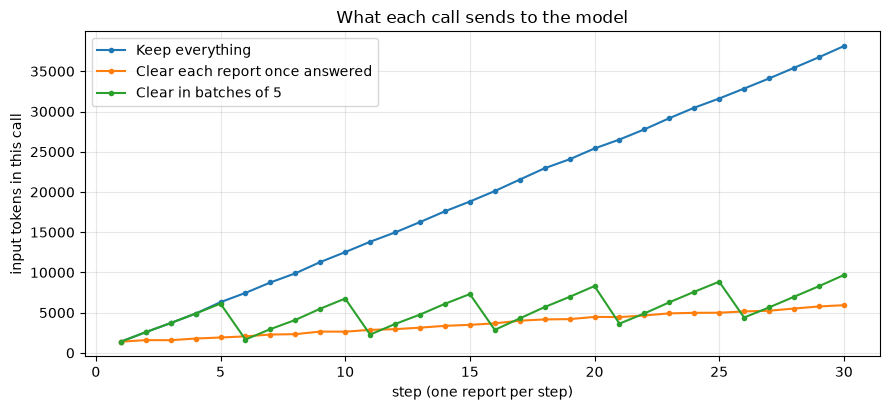

In [7]:
runs = {"Keep everything": (keep_answers, keep_log),
        "Clear each report once answered": (clear_answers, clear_log),
        "Clear in batches of 5": (batch_answers, batch_log)}

print(f"{'':34}{'input sent':>12}{'cached':>8}{'last call':>11}{'cost':>8}{'caught':>8}{'wrong cap':>10}")
for name, (a, lg) in runs.items():
    s, sent = score(a), sum(r["input"] for r in lg)
    print(f"{name:34}{sent:>12,}{sum(r['cached'] for r in lg) / sent:>8.0%}{lg[-1]['input']:>11,}"
          f"{'$' + format(cost(lg), '.3f'):>8}{str(s['caught']) + '/' + str(len(TRUTH)):>8}{len(s['wrong_cap']):>10}")

plt.figure(figsize=(9, 4.2))
for name, (_, lg) in runs.items():
    plt.plot([r["step"] for r in lg], [r["input"] for r in lg], marker=".", label=name)
plt.xlabel("step (one report per step)"); plt.ylabel("input tokens in this call")
plt.title("What each call sends to the model"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

### What the numbers say, and what they don't

- **Tokens.** Keeping everything sends far more tokens per run, and the size of each call grows with every report. Clearing keeps each call close to flat: the policy, one report, and a line per finished report. Batching gives the sawtooth.
- **Dollars.** The gap in dollars is much smaller than the gap in tokens: clearing every step sent about a fifth of the tokens and saved under 10%, because the append-only history was 94% cached. Batching was the cheapest run here. It sent more tokens than clearing every step, but most of its calls still repeated the previous prefix, so 71% of what it sent was billed at the cached price. In two earlier runs of the same setup (not shown), the two clearing modes cost about the same, so treat the dollar differences as small and noisy, and measure your own runs before you design around them.
- **Quality.** At this size (the last call of the default loop is under 40K tokens), no mode ever checked a hotel night against the wrong city's cap. Recall is closer. Across this run and two earlier ones, keeping everything caught 11, 10 and 9 of the 11 planted violations, and clearing every step caught 11 each time. The default loop missed R-24, one of the late reports, in two of its three runs, and the clearing modes never missed it in six. That is a hint, not proof: three runs per mode is too few, and R-03, an early report where the contexts barely differ, was also missed twice. **This notebook does not prove clearing makes the model more accurate at 30 reports.** Quality loss from long contexts, "context rot", has been measured at larger sizes and with harder distractors ([Chroma, 2025](https://www.trychroma.com/research/context-rot)). To look for it on your model, raise `n` in `make_reports` and watch the `caught` and `wrong cap` columns.
- **What clearing buys you for sure** is room. The default loop's calls grow by about 1,270 tokens per report, so 300 reports would put roughly 380K tokens in the last call, more than many models' windows hold. With clearing, the history grows by about 150 tokens per report (the one-line stub plus the agent's answer), so the same 300 reports would end under 50K.

## 6. An aside the data forced on us: the false alarms

Every mode produced false alarms: 10, 20 and 12 in this run, and anywhere from 12 to 20 in the two earlier runs, with no consistent pattern by mode. So they are not a context effect. Look at what the model actually wrote:

In [8]:
for rid, vs in keep_answers.items():
    for v in vs:
        if (rid, v["rule"]) not in TRUTH and v["rule"] == "H":
            print(f"{rid}: listed as a violation -> amount {v['amount']:g}, limit {v['limit']:g}   ({v['receipt'][:60]})")
            break

R-04: listed as a violation -> amount 230, limit 260   (2026-09-06  Hotel: The Verb Hotel, Boston - 1 night - $230.0)
R-08: listed as a violation -> amount 310, limit 320   (2026-09-12  Hotel: The Lexington, New York - 1 night - $310.)
R-12: listed as a violation -> amount 205, limit 210   (2026-09-16  Hotel: The Driskill, Austin - 1 night - $205.00)
R-13: listed as a violation -> amount 290, limit 300   (2026-09-16  Hotel: Hotel Zephyr, San Francisco - 1 night - $)
R-15: listed as a violation -> amount 305, limit 320   (2026-09-01  Hotel: The Lexington, New York - 1 night - $305.)
R-19: listed as a violation -> amount 205, limit 210   (2026-09-13  Hotel: The Driskill, Austin - 1 night - $205.00)
R-21: listed as a violation -> amount 220, limit 240   (2026-09-12  Hotel: The Robey, Chicago - 1 night - $220.00)
R-27: listed as a violation -> amount 270, limit 300   (2026-09-15  Hotel: Hotel Zephyr, San Francisco - 1 night - $)
R-29: listed as a violation -> amount 305, limit 320   (2026-

In every case printed above, the model wrote down an amount *below* the limit it named, and still listed the receipt as a violation. Moving rules around in the context will not fix that: the model extracted the right numbers and then got the comparison wrong. The fix is the one from the [while-loop notebook](agent_while_loop_from_scratch.ipynb): anything that must hold belongs in code. Let the model do what it is good at, reading a messy report and pulling out the receipt, the amount and the right city's cap, and let a line of Python do the comparison:

In [9]:
def checked_by_code(answers):
    return {rid: [v for v in vs if v["rule"] == "D" or v["amount"] > v["limit"]] for rid, vs in answers.items()}

for name, (a, _) in runs.items():
    before, after = score(a), score(checked_by_code(a))
    print(f"{name:34} false alarms {len(before['false_alarms']):>2} -> {len(after['false_alarms']):>2}   caught {before['caught']} -> {after['caught']}")

Keep everything                    false alarms 10 ->  0   caught 9 -> 9
Clear each report once answered    false alarms 20 ->  0   caught 11 -> 11
Clear in batches of 5              false alarms 12 ->  0   caught 10 -> 10


## The fact to walk away with

The bare loop never forgets, so by step 30 it re-reads 29 reports it already finished. Replacing a result with a one-line finding once the agent has acted on it costs no model call and keeps every call close to the same size, however long the run gets. At 30 reports, on a current model, it did not clearly change the audit's quality, and with prompt caching it saved far less money than the token count suggests. Measure your own runs before you believe any of these claims, including the ones in this notebook.

What to try next, in the order the chapter recommends:

- **Cap results on arrival.** Keep the head and tail of a huge tool result, write the full text to a file, and leave the path in the window. Always mark the cut, because an unmarked cut looks like a whole result.
- **Restate the rule that matters beside new material**, if instructions start fading late in long runs.
- **Compact** only when history still outgrows its budget after clearing. Use a summary with fixed headings (task, decisions, exact values, what failed, what is left), because every summary silently drops something.

---
📖 **Want the decisions behind agents like this one, explained without code?** [*AI Agents Made Simple*](https://europe-west1-rag-techniques-views-tracker.cloudfunctions.net/rag-techniques-tracker?notebook=all-agents-tutorials--context-engineering-from-scratch&click=book-nb-agents&target=https%3A%2F%2Fwww.amazon.com%2Fdp%2FB0HNXRSRH2%3Fmaas%3Dmaas_adg_api_580351185840460851_static_9_573%26ref_%3Daa_maas%26tag%3Dmaas%26aa_campaignid%3Dagents-en%26aa_adgroupid%3Dgithub-notebook%26aa_creativeid%3Dgenai-context-engineering&retarget=0&text=book-nb-agents) by the author of this repository has a full chapter on context engineering: the five layers, context budgets, compaction and what it loses, and when all of it is overkill. Available on Amazon.